# My First Machine Learning: Helping a Netball Coach

**The story:** you help the coach of the made-up team **Hack City Hawks**. The coach asks:

> *"Should we spend training time on **shooting** or on **defence**?"*

We'll answer using **3 machine learning models**:

| Model | Question it answers | Answer type |
| --- | --- | --- |
| Linear Regression | How many goals will we score? | A **number** |
| Logistic Regression | Will we win? | **Yes / No** (as a %) |
| Neural Network | Which plan gives the best chance to win? | **Yes / No** (as a %) |

**How to run:** click a grey code cell and press **Shift + Enter**. Run the cells in order, top to bottom.

## What is Machine Learning?

Normal programming: **you** write the rules.
Machine learning: **the computer finds the rules** by looking at lots of examples.

Example: show the computer 50 past matches, and it learns *"teams that shoot better usually score more"*.

## Step 1: Get the tools ready

Just run this cell. It loads the Python libraries we need.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

## Step 2: Make some pretend match data

We'll invent **50 past matches** for the Hawks. Each row is one match:

- `shooting` is the % of shots that went in
- `gains` is the number of times we won the ball back from the other team
- `goals` is how many goals we scored
- `win` is 1 if we won and 0 if we lost

You don't need to understand this cell. Just run it.

In [2]:
np.random.seed(1)
shooting = np.random.randint(75, 95, 50)
gains = np.random.randint(5, 20, 50)
goals = (0.5 * shooting + 1.2 * gains + np.random.normal(0, 3, 50)).round()
win = (goals > np.random.normal(58, 4, 50)).astype(int)

matches = pd.DataFrame({"shooting": shooting, "gains": gains, "goals": goals, "win": win})
matches.head()

,shooting,gains,goals,win
0,80,8,50.0,0
1,86,14,63.0,1
2,87,7,55.0,1
3,83,5,47.0,0
4,84,9,55.0,0


---
## Model 1: Linear Regression

**Question:** *If our shooting gets better, how many goals will we score?*

Linear regression draws the **best straight line** through the dots. You may know the line equation from maths:

$$y = mx + b$$

- $x$ = shooting %
- $y$ = goals
- $m$ = the **slope**, i.e. how many extra goals we get for each +1% of shooting

### 1a. Look at the data first

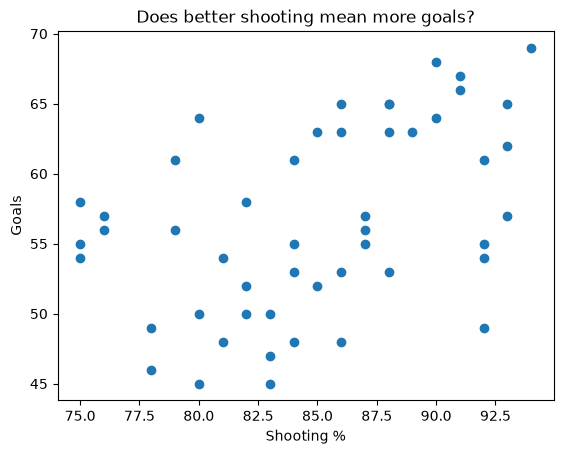

In [3]:
plt.scatter(matches["shooting"], matches["goals"])
plt.xlabel("Shooting %")
plt.ylabel("Goals")
plt.title("Does better shooting mean more goals?")
plt.show()

### 1b. Train the model

**Training** means the computer looks at the data and finds the best line.

In [4]:
X = matches[["shooting"]]   # the input
y = matches["goals"]        # what we want to predict

line_model = LinearRegression()
line_model.fit(X, y)        # fit = train

print("Slope (m):", round(line_model.coef_[0], 2), "extra goals for every +1% shooting")

Slope (m): 0.55 extra goals for every +1% shooting


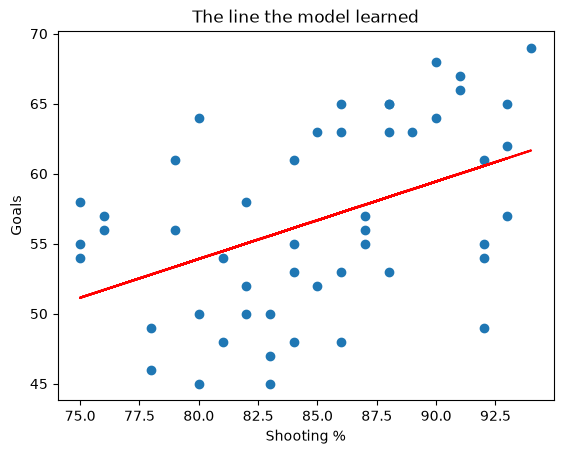

In [5]:
plt.scatter(matches["shooting"], matches["goals"])
plt.plot(matches["shooting"], line_model.predict(X), color="red")
plt.xlabel("Shooting %")
plt.ylabel("Goals")
plt.title("The line the model learned")
plt.show()

### 1c. Make a prediction

✏️ **Try it:** change `85` to another number and run the cell again.

In [7]:
my_shooting = 55
predicted_goals = line_model.predict(pd.DataFrame({"shooting": [my_shooting]}))
print("With", my_shooting, "% shooting, we expect about", round(predicted_goals[0]), "goals")

With 55 % shooting, we expect about 40 goals


---
## Model 2: Logistic Regression

**Question:** *How many goals do we need to win?*

This time the answer is **yes or no** (win or lose), not a number. Logistic regression gives a **chance between 0% and 100%**, and its graph is an **S-shaped curve**.

> Even though it's called "regression", it's used for **yes/no** questions.

In [8]:
X = matches[["goals"]]
y = matches["win"]

win_model = LogisticRegression()
win_model.fit(X, y)

print("Model trained!")

Model trained!


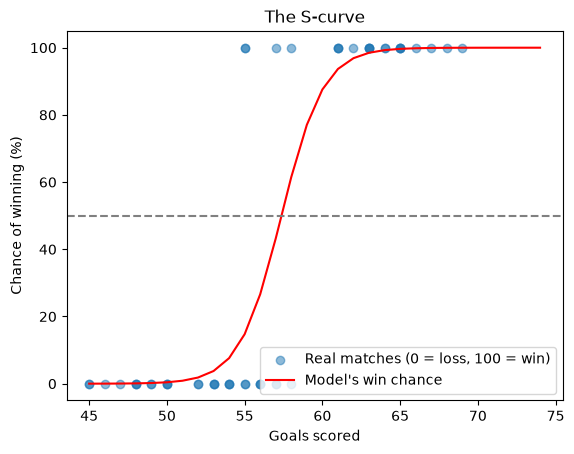

In [9]:
goal_range = pd.DataFrame({"goals": range(45, 75)})
win_chance = win_model.predict_proba(goal_range)[:, 1] * 100

plt.scatter(matches["goals"], matches["win"] * 100, alpha=0.5, label="Real matches (0 = loss, 100 = win)")
plt.plot(goal_range["goals"], win_chance, color="red", label="Model's win chance")
plt.axhline(50, color="grey", linestyle="--")
plt.xlabel("Goals scored")
plt.ylabel("Chance of winning (%)")
plt.title("The S-curve")
plt.legend()
plt.show()

✏️ **Try it:** what is our chance of winning if we score 60 goals? Change the number.

In [11]:
my_goals = 60
chance = win_model.predict_proba(pd.DataFrame({"goals": [my_goals]}))[0, 1] * 100
print("Scoring", my_goals, "goals gives about a", round(chance), "% chance of winning")

Scoring 60 goals gives about a 88 % chance of winning


---
## Model 3: Neural Network

**Question:** *Should we train **shooting** or **defence (gains)**?*

A neural network is loosely based on how a brain works. It has **layers of "neurons"** connected together:

```
  shooting ─┐                  ┌─ neuron ─┐
            ├──▶ neurons ──▶  ─┤          ├──▶  chance of winning
  gains ────┘                  └─ neuron ─┘
   INPUT        HIDDEN LAYER               OUTPUT
```

While it trains, the network adjusts the **strength of each connection** until its guesses get better. It can learn more complicated patterns than a straight line, but it needs **lots of data**.

In [12]:
X = matches[["shooting", "gains"]]
y = matches["win"]

# StandardScaler puts shooting (75-95) and gains (5-20) on the same scale; neural networks need this
brain = make_pipeline(
    StandardScaler(),
    MLPClassifier(hidden_layer_sizes=(5,), solver="lbfgs", alpha=1.0, max_iter=2000, random_state=1),
)
brain.fit(X, y)

print("Neural network trained! It got", round(brain.score(X, y) * 100), "% of the past matches right.")

Neural network trained! It got 86 % of the past matches right.


### Make the decision

Our **average** match is about 85% shooting and 12 gains. The coach has two options:

- **Plan A, shooting training:** shooting goes up to **90%**
- **Plan B, defence training:** gains go up to **17**

Let's ask the neural network.

In [15]:
plans = pd.DataFrame({
    "shooting": [85, 90, 85],
    "gains":    [12, 14, 17],
}, index=["Now", "Plan A: Shooting", "Plan B: Defence"])

plans["Win chance %"] = (brain.predict_proba(plans)[:, 1] * 100).round()
plans

,shooting,gains,Win chance %
Now,85,12,42.0
Plan A: Shooting,90,14,80.0
Plan B: Defence,85,17,86.0


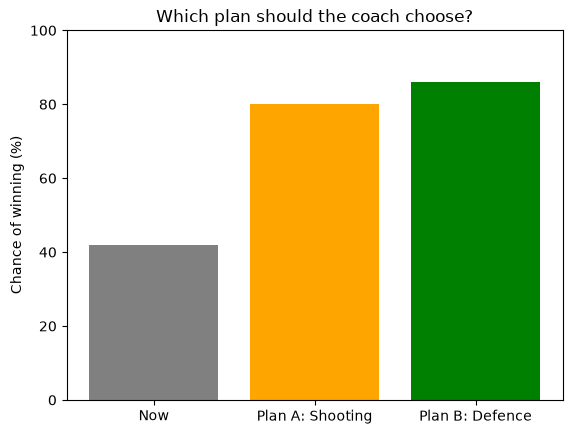

In [16]:
plt.bar(plans.index, plans["Win chance %"], color=["grey", "orange", "green"])
plt.ylabel("Chance of winning (%)")
plt.title("Which plan should the coach choose?")
plt.ylim(0, 100)
plt.show()

✏️ **Try it:** change the numbers in the `plans` cell. What if Plan B only gave **14** gains?

---
## What did we learn?

| Model | What it predicts | Our example |
| --- | --- | --- |
| **Linear Regression** | A number | Goals from shooting % |
| **Logistic Regression** | Yes/No chance | Win chance from goals |
| **Neural Network** | Yes/No chance (more complex patterns) | Win chance from shooting **and** gains |

### Talk about it with your team
1. Which plan would **you** tell the coach to pick? Why?
2. The data was **made up**. Would you trust this for a real team?
3. What important things does the model **not** know? (Injuries? The other team? The weather?)

> **Big idea:** ML gives us **evidence** to help make decisions. It is not always right, so always check if the answer makes sense!

**Next:** try these models on the real netball data with `4_ML_Intro_and_AI_Prompts.ipynb`.